In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

Lab journal Onderzoekspracticum

Bram Reekers & Vera Reeringh


31-8-2026

1.1 

We hebben de string een paar keer geplukt en we vonden verschillende signalen. We experimenteerden een een beetje met de spanning, en verlaagde deze eerst ten opzichte van de spanning van de oorspronkelijke opstelling. Nadat we de trigger op de oscilloscoop naar links verplaatsten (1.1.3), kregen we geen mooie sinus. Daarna voerden we de spanning van de string weer op. Bij verschillende spanningen kregen we alsnog geen mooie sinus. Er kwam geen duidelijke oorzaak naar boven van het suboptimale resultaat.


Toch lukte het , na enkele instellingen om een goed signaal vanaf de trigger te krijgen.


De Username is ShareUser van de Siglent Oscilloscoop om te verbinden met de laptop

Het opslaan van het signaal was eerst niet mogelijk omdat er iets was misgegaan met de channels, we hebben het probleem opgelost door weer terug naar channel 1 te navigeren. Hieronder een screenshot van het resultaat.


<img src="signaal1.1.png" alt="screenshot signaal 1.1" width="1000"/>

1.3 31-8-2026

Hieronder is een screenshot van ons signaal van de fourier functie van de oscillator


<img src="Fouriertransform1.3.png" alt="screenshot signaal 1.3" width="1000"/>

In [9]:
# # data van 1.3 analyseren
# # Doel is om een frequentie - amplitude  plot te krijgen

# df = pd.read_csv ("FFTdata1.3.csv", skiprows=12, names = ["Time", "Amplitude"])

# array_FFT = np.fft.fft(df["Amplitude"].values) # amplitudes

# print(array_FFT)

# # 1. Bepaal het tijdsinterval (dt) en aantal datapunten (N)
# N = len(df)
# dt = df["Time"].iloc[1] - df["Time"].iloc[0]  # Tijd tussen twee opeenvolgende metingen
# freqs = np.fft.fftfreq(N, d=dt) # frequenties

# # 3. Filter alleen de positieve frequenties, omdat FFT de frequenties spiegelt
# pos_filter = freqs >= 0
# frequentie = freqs[pos_filter]

# # Amplitude schalen (factor 2/N ivm spiegeling en lengte van het signaal)
# amplitude = (2.0 / N) * np.abs(array_FFT[pos_filter])

# plt.figure()

# plt.plot(frequentie, amplitude, color='b')
# plt.xlabel( "Frequentie (Hz)")
# plt.ylabel("Amplitude")
# plt.xlim(0,1)
# plt.show()


Zoals hierboven te zien is, klopt de code voor de plot van de Fourier transformatie nog niet. Deze gaan we later verbeteren, om nu verder te gaan met de onderzoeksvraag.

In [10]:
# # nieuwe plot, van de rauwe data

# x_array = df["Time"].values
# y_array = df["Amplitude"].values

# plt.figure()
# plt.plot (x_array, y_array, color = 'b')
# plt.xlim(0,5) # 5 seconden laten zien
# plt.grid()
# plt.show()

Onze eerste opzet voor een onderzoeksvraag is: hoe hangt de uitrekking van de draad af met de spanning in de draad. We willen dit berekenen aan de hand van de massadichtheid mu, de spanning T en de golfsnelheid v en hun relatie ( v = wortel (T / mu)). Mu zal namelijk kleiner worden als de snaar uitrekt, waardoor de lengte en de uitrekking te berekenen valt. 

In [11]:
#poging 2 fft



**7-9-2026 Tweede Labsessie**

Het doel van deze labsessie is om 8 meetpunten te hebben voor om een fit te maken voor mu bij de eerste resonantiefrequentie. 
We meten bij 8 verschillende spanningen bij 1 lengte.

In [12]:
# DATA

# frequentie data
# we hebben voor elke positie 5x handmatig de snaar geplukt om de eerste resonantiefrequentie te meten
data = {
    "300_4": [152.5, 152.5, 152.2, 152.1, 152.1],
    "300_6": [159.6, 159.5, 159.6, 159.6, 159.6],
    "300_8": [161.8, 161.4, 161.8, 161.4, 161.5],
    "300_10": [167.4, 167.5, 167.4, 167.3, 167.1],

    "500_4": [172.6, 172.6, 172.7, 172.6, 172.6],
    "500_6": [178.1, 178.9, 178.9, 178.9, 178.9],
    "500_8": [207.7, 207.5, 207.5, 207.5, 209.6],
    "500_10": [203.8, 201.6, 202.9, 202.5, 203.8],

    "800_4": [170.9, 170.5, 170.6, 170.5, 170.5],
    "800_6": [192.3, 191.5, 191.5, 191.5, 191.5],
    "800_8": [210.2, 210.0, 209.9, 209.0, 209.0],
    "800_10": [239.6, 239.2, 239.2, 238.8, 238.4],

    "1000_4": [180.8, 178.9, 182.3, 182.0, 182.3],
    "1000_6": [209.4, 209.4, 209.4, 209.1, 209.4],
    "1000_8": [200.2, 200.6, 200.3, 200, 200],
    "1000_10": [285.0, 284.8, 284.2, 284.2, 284.2],

    "1500_4": [238.0, 238.4, 238.4, 238.4, 238.4],
    "1500_6": [292.6, 292.6, 292.6, 292.6, 292.6],
    "1500_8": [294.9, 294.1, 293.7, 293.3, 293.0],
    "1500_10": [279.3, 278.9, 279.3, 278.9, 279.3]
}

gemiddelden = np.array([np.mean(x) for x in data.values()])
onzekerheid = np.array([(np.std(x)/np.sqrt(5)) for x in data.values()])

#hefboom data
hefboom_array = np.array([0.3093 * 4, 0.3093 * 6, 0.3093 * 8, 0.3093 * 10,
                          0.4973*4 , 0.4973*6 , 0.4973*8, 0.4973*10, 
                          0.7777* 4, 0.7777 * 6, 0.7777 * 8, 0.7777 * 10,
                          1.0452 * 4, 1.0452 * 6, 1.0452 * 8, 1.0452 * 10, 
                          1.5287 * 4, 1.5287 * 6, 1.5287 * 8, 1.5287 * 10])

spanning_array = hefboom_array * 9.81

L_draad = 0.5470 # [m]
u_T = 9.81 * 0.0001
u_L = 0.0001


In [13]:
#Functies
f1_array = gemiddelden


def bereken_mu(T,L,f):
    mu =  T/( 4* L**2 *f**2)
    return mu

mu_array = bereken_mu(spanning_array, L_draad, gemiddelden)

def bereken_u_mu(T, L, f, u_T, u_L, u_f):
    part_T = 1 / (4 * L**2 * f**2)
    part_L = -T / (2 * L**3 * f**2)
    part_f = -T / (2 * L**2 * f**3)

    return np.sqrt(
        (part_T * u_T)**2 +
        (part_L * u_L)**2 +
        (part_f * u_f)**2
    )

u_mu_array = bereken_u_mu(spanning_array, L_draad, f1_array, u_T, u_L, onzekerheid)

print("mu_array =", mu_array)
print("u_mu_array =", u_mu_array)

# eerste plot : frequenties tegenover mu

# de curvefit functie definieren

def fitfunc1 (T,mu):
    boven =  np.sqrt(T)
    onder = 2 * 0.547 * np.sqrt(mu) # met lengte van de snaar in de functie
    f = boven / onder
    return f

# curve fit voor mu

popt, pcov = curve_fit (fitfunc1, spanning_array, f1_array, bounds=(0, np.inf))
mu = popt[0]
print ("mu =", mu)

# arrays voor de fit

span_ar = np.linspace(0,200,400)


def youngfit(T, a, m):
    f = 1/(2*L_draad) * np.sqrt((L_draad * T**2 + a * T)/m)
    return f

popt2, pcov2 = curve_fit (youngfit, spanning_array, f1_array, bounds=(0, np.inf))
print(popt2)

youngfitarray = youngfit(span_ar, *popt2)

def youngmodel(T):
    a, m = popt2
    mu = m/(L_draad + a*T)
    return mu
    

mu_array = [0.00043731 0.00059732 0.00077684 0.00090535 0.00054718 0.00076553
 0.00075402 0.00098993 0.00087609 0.0010412  0.00116057 0.00111559
 0.00104301 0.00117295 0.00170966 0.0010586  0.00088246 0.00087813
 0.0011613  0.0016081 ]
u_mu_array = [4.98490071e-07 2.58201407e-07 8.38437216e-07 7.35727007e-07
 2.31612791e-07 1.25765100e-06 2.68536382e-06 3.65197550e-06
 7.80857685e-07 1.60096647e-06 2.58720231e-06 1.75100389e-06
 6.71825737e-06 7.38880580e-07 1.81227614e-06 1.22350106e-06
 6.20577563e-07 3.21214316e-07 2.38325505e-06 1.16848367e-06]
mu = 0.0010581994774343732
[2.08793780e+09 2.20945474e+06]


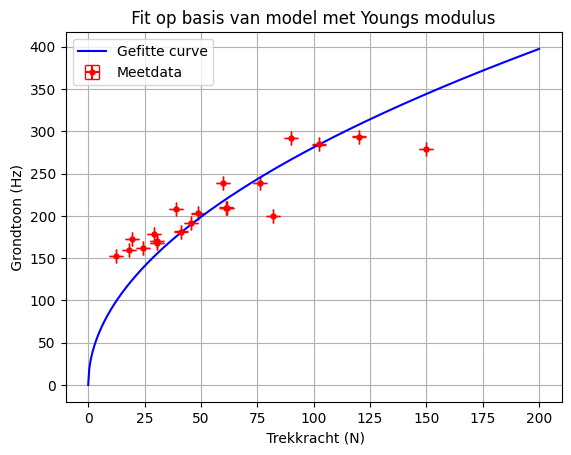

<Figure size 640x480 with 0 Axes>

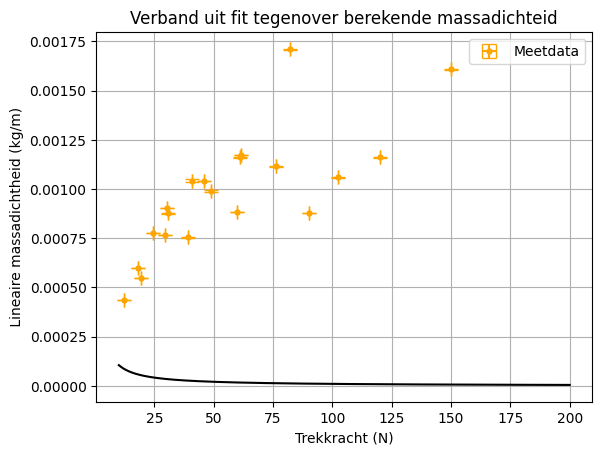

<Figure size 640x480 with 0 Axes>

In [14]:
#plots


plt.figure()
plt.errorbar(spanning_array, f1_array,xerr = u_T , yerr= onzekerheid ,fmt = 'o',capsize = 5,markersize =3.55, color ='r', label='Meetdata',ecolor = "r")
plt.plot(span_ar, youngfitarray , '-', color ='b', label = 'Gefitte curve')
plt.title (" Fit op basis van model met Youngs modulus ")
plt.xlabel( " Trekkracht (N)")
plt.ylabel(" Grondtoon (Hz) ")
plt.legend()
plt.grid()
plt.show()
plt.savefig(
    "resonantiefrequentie.png",
    dpi=600,
    bbox_inches="tight"
)

cust_ar = np.linspace(10,200,400)

plt.figure()
plt.errorbar(spanning_array,mu_array,xerr= u_T,yerr = u_mu_array, fmt = 'o', capsize = 5,markersize =3.55, color ='orange', label='Meetdata',ecolor = "orange")
plt.plot(cust_ar,youngmodel(cust_ar), color ='black', )
plt.title ("Verband uit fit tegenover berekende massadichteid")
plt.legend()
plt.xlabel( "Trekkracht (N)")
plt.ylabel(" Lineaire massadichtheid (kg/m) ")
plt.grid()
plt.show()
plt.savefig(
    "mu.png",
    dpi=600,
    bbox_inches="tight"
)







Wat er allemaal inaccuraat kan zijn:

 de frequentie waarop we de snaar (willen) laten trillen

De siglent zegt steeds dat de eerste peak op 50 Hz ligt. We vragen ons af of dit aan het apparaat ligt of niet, want er lijkt iets niet te veranderen.
Het lag aan een defecte kabel. We hebben per ongeluk het stopcontact gemeten (50 Hz).

We hebben eerst best wel lang gestruggeld om het apparaat werkende te krijgen.

De frequentie wilde steeds niet veranderen bij het experiment dat we uitvoerden, terwijl dat wel moest. Daarom gingen we over op met de hand aanslaan, in plaats van de functie generator te gebruiken.

<img src="aant7-9.jpeg" alt = "aantekeningen tweede labsessie" width = "500" />

<img src = "aant7-92.jpeg" alt = "aantekeningen tweede labsessie" width = "500"/>

14-9-2026


Vandaag duurde het eerst erg lang om onze opstelling weer op te bouwen omdat de opstelling door een andere groep uit elkaar was gehaald. dat kostte een goed anderhalf uur. Daardoor hadden we helaas minder tijd voor het meten op hogere spanning.
De meting van 1 kilo op 8 en 1.5 kilo op 10 schoot heel erg uit, daarom hebben we deze er uit gehaald.

